# Practical tasks

##### Please explore the datasets and answer the questions below.
##### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_moons
from sklearn.metrics import silhouette_score, classification_report, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import AgglomerativeClustering

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


# Clustering tasks

The problem that we are going to solve in this section is to segment customers into different groups based on their shopping trends.

The dataset for this problem `shopping-data.csv`

#### 1. Load the data and preview

In [2]:
customer_data = pd.read_csv('shopping-data.csv')

In [3]:
customer_data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
customer_data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


#### 2. Plot scatter plot for annual income and spending score which will be used for clustering in the next steps

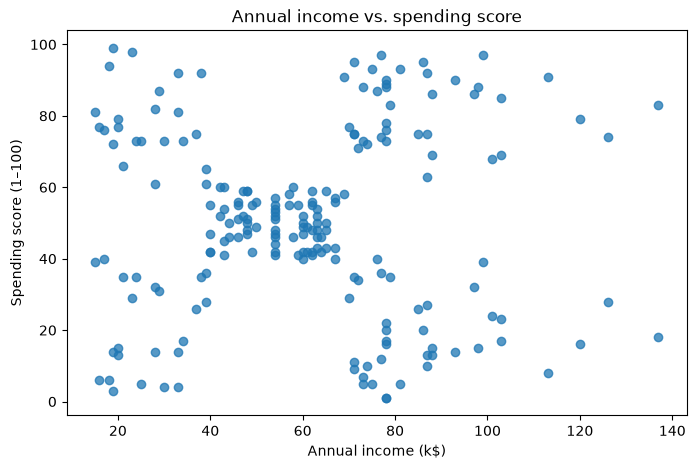

In [ ]:
shopping_features = customer_data[["Annual Income (k$)", "Spending Score (1-100)"]]
plt.figure(figsize=(8, 5))
plt.scatter(shopping_features["Annual Income (k$)"],
            shopping_features["Spending Score (1-100)"], alpha=0.75)
plt.xlabel("Annual income (k$)")
plt.ylabel("Spending score (1–100)")
plt.title("Annual income vs. spending score")
plt.show()

#### 3. Normalize the data

In [6]:
shopping_scaler = StandardScaler()
X_shopping = shopping_scaler.fit_transform(shopping_features)
pd.DataFrame(X_shopping, columns=shopping_features.columns).head()

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


#### 4. Use Elbow method to decide number of clusters

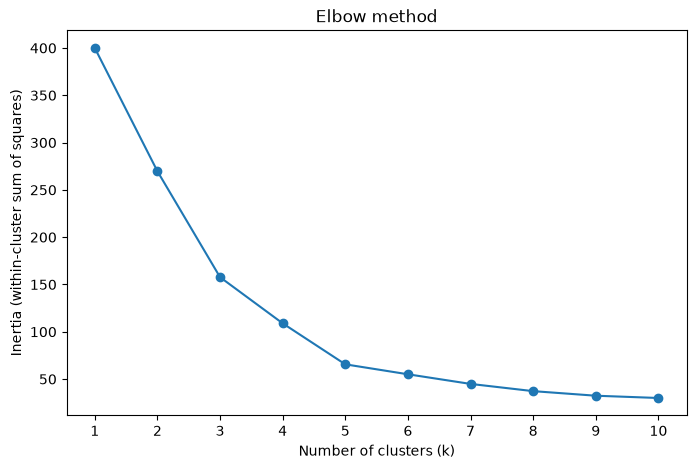

In [7]:
inertias = []
k_values = range(1, 11)
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_shopping)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.title("Elbow method")
plt.xticks(list(k_values))
plt.show()

#### 5. Perform Clustering using KMeans

In [8]:
kmeans_shopping = KMeans(n_clusters=5, random_state=42, n_init=10)
shopping_kmeans_labels = kmeans_shopping.fit_predict(X_shopping)
customer_data["KMeans cluster"] = shopping_kmeans_labels
customer_data["KMeans cluster"].value_counts().sort_index()

KMeans cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

#### 6. Plot scatter plot and color code in clustered groups

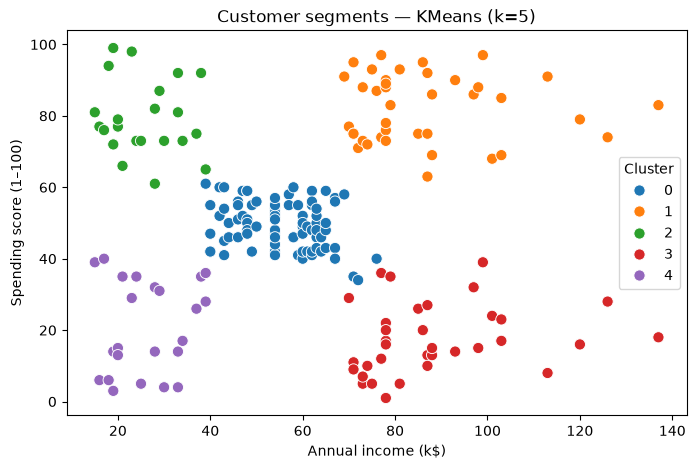

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=customer_data, x="Annual Income (k$)",
                y="Spending Score (1-100)", hue="KMeans cluster",
                palette="tab10", s=65)
plt.title("Customer segments — KMeans (k=5)")
plt.xlabel("Annual income (k$)")
plt.ylabel("Spending score (1–100)")
plt.legend(title="Cluster")
plt.show()

#### 7. Plot dendrogram to decide number of clusters for Hierarchical Clustering. <br> Explain (free text in a markdown cell) what is the optimal number of clusters and why

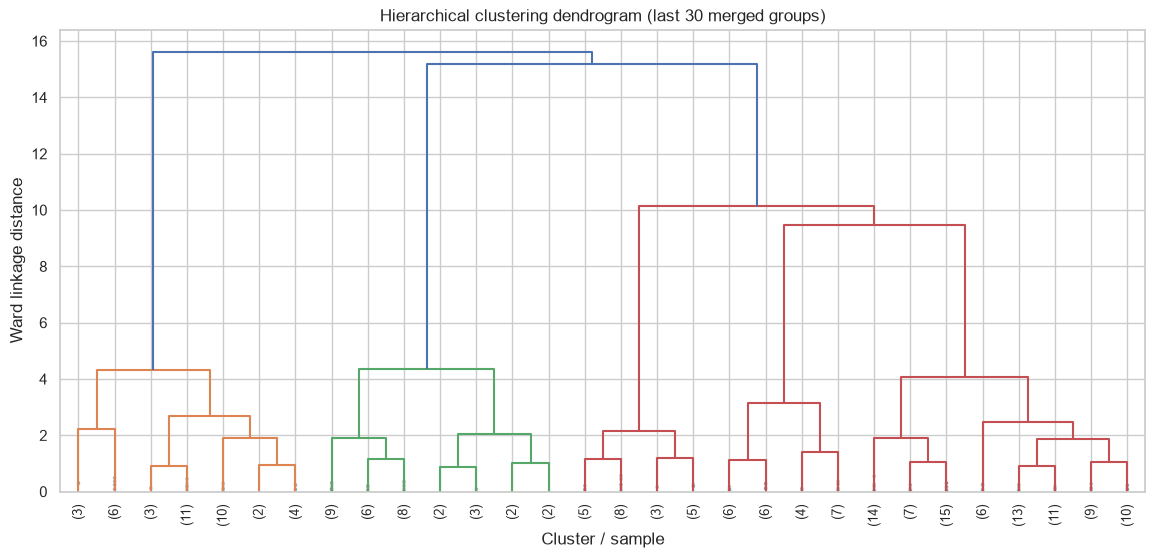

In [13]:
Z = linkage(X_shopping, method="ward")
plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90,
           leaf_font_size=9, show_contracted=True)
plt.title("Hierarchical clustering dendrogram (last 30 merged groups)")
plt.xlabel("Cluster / sample")
plt.ylabel("Ward linkage distance")
plt.show()

#### 8. Do clustering using Hierarchical Clustering

In [14]:
hierarchical = AgglomerativeClustering(n_clusters=5, linkage="ward")
shopping_hier_labels = hierarchical.fit_predict(X_shopping)
customer_data["Hierarchical cluster"] = shopping_hier_labels
pd.Series(shopping_hier_labels).value_counts().sort_index()

0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64

#### 9. Plot scatter plot and color code in clustered groups

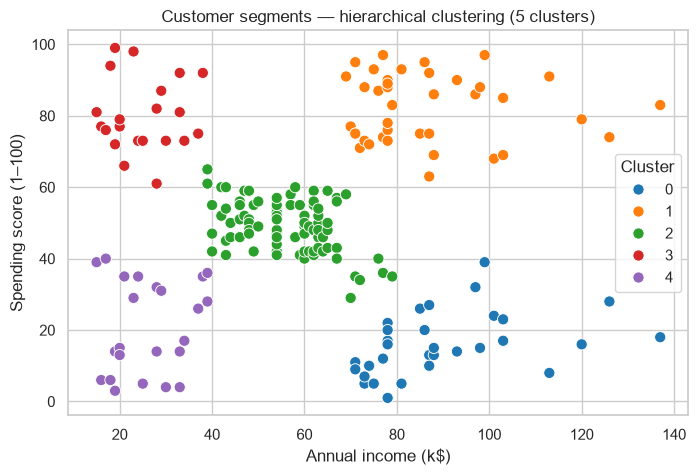

In [15]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=customer_data, x="Annual Income (k$)",
                y="Spending Score (1-100)", hue="Hierarchical cluster",
                palette="tab10", s=65)
plt.title("Customer segments — hierarchical clustering (5 clusters)")
plt.xlabel("Annual income (k$)")
plt.ylabel("Spending score (1–100)")
plt.legend(title="Cluster")
plt.show()

####  10. Do KMeans and DBSCAN clustering on this data

In [16]:
from sklearn.datasets import make_moons
#moons_X: Data, moon_y: Labels
moons_X, moon_y = make_moons(n_samples=2000)

Text(0.5, 1.0, 'Half Moons')

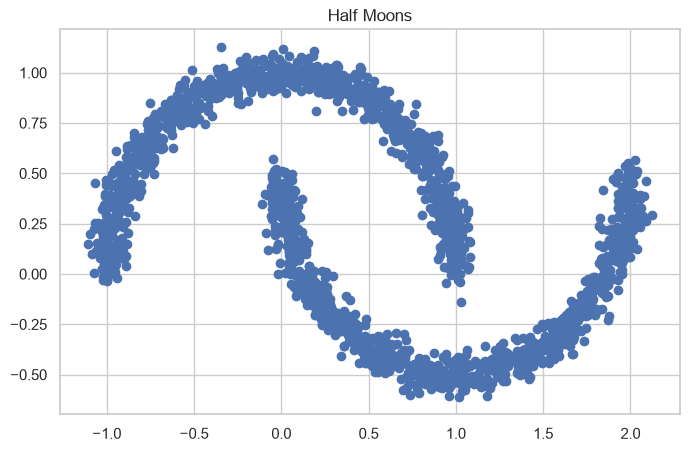

In [20]:
plt.scatter(moons_X[:,0],moons_X[:,1])
plt.title('Half Moons')

#### Using KMeans (do clustering and plot results (each cluster in own color))

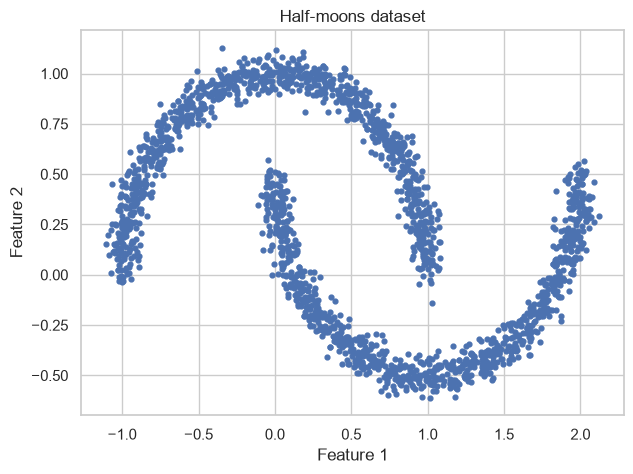

In [ ]:
moons_X, moon_y = make_moons(n_samples=2000, noise=0.05, random_state=42)
plt.figure(figsize=(7, 5))
plt.scatter(moons_X[:, 0], moons_X[:, 1], s=12)
plt.title("Half-moons dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Text(0.5, 1.0, 'Half Moons')

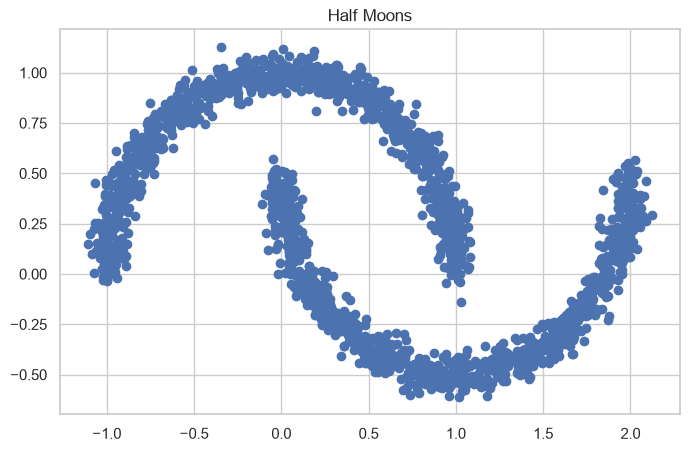

In [23]:
plt.scatter(moons_X[:,0],moons_X[:,1])
plt.title('Half Moons')

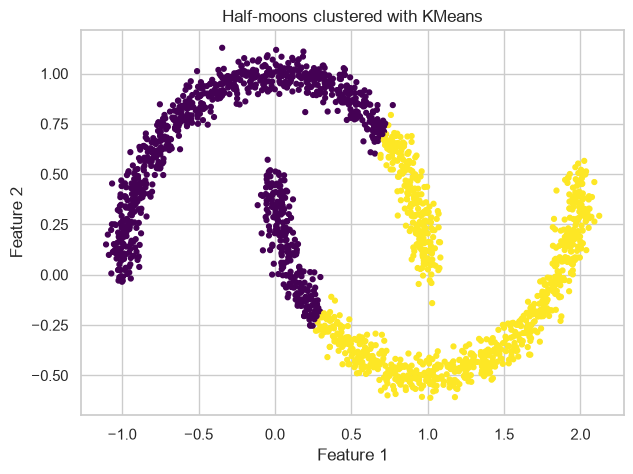

In [25]:
kmeans_moons = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_moons_labels = kmeans_moons.fit_predict(moons_X)
plt.figure(figsize=(7, 5))
plt.scatter(moons_X[:, 0], moons_X[:, 1], c=kmeans_moons_labels,
            cmap="viridis", s=12)
plt.title("Half-moons clustered with KMeans")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

#### 11. Using DBSCAN do clustering and plot results (each cluster in own color). Find the most suitable eps and minimal samples number

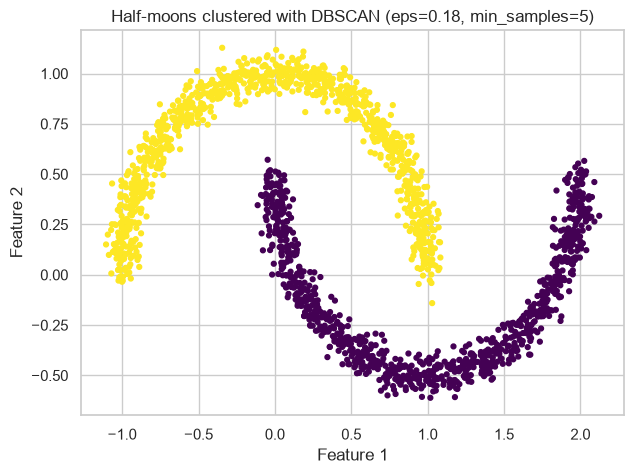

Number of clusters: 2
Number of noise points: 0


In [26]:
dbscan_results = []
for eps in np.arange(0.10, 0.31, 0.02):
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(moons_X)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int(np.sum(labels == -1))
    dbscan_results.append((round(float(eps), 2), n_clusters, n_noise))
pd.DataFrame(dbscan_results, columns=["eps", "clusters", "noise points"])
best_eps, best_min_samples = 0.18, 5
dbscan_moons = DBSCAN(eps=best_eps, min_samples=best_min_samples)
dbscan_moons_labels = dbscan_moons.fit_predict(moons_X)
plt.figure(figsize=(7, 5))
plt.scatter(moons_X[:, 0], moons_X[:, 1], c=dbscan_moons_labels,
            cmap="viridis", s=12)
plt.title(f"Half-moons clustered with DBSCAN (eps={best_eps}, min_samples={best_min_samples})")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()
print("Number of clusters:", len(set(dbscan_moons_labels)) - (1 if -1 in dbscan_moons_labels else 0))
print("Number of noise points:", int(np.sum(dbscan_moons_labels == -1)))


#### 12. Compare the results of K-means and DBSCAN clustering
Explain why one or another is prefferable for such dataset, and differences if any.

### Perform PCA on penguins :)
###### This section uses kaggle dataset (https://www.kaggle.com/datasets/youssefaboelwafa/clustering-penguins-species/data)
###### The tasks below include data analysis, data preprocessing, PCA, and application of classification to predict the target

#### 13. Describe the data. Do any additional exporations as you feel

In [27]:
# Dataset
penguins = pd.read_csv('penguins.csv')
penguins.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [28]:
print("Shape:", penguins.shape)
print("\nData types:")
display(penguins.dtypes)
print("\nSummary:")
display(penguins.describe(include="all"))
print("\nSex counts (including missing/invalid values):")
display(penguins["sex"].value_counts(dropna=False))
print("\nFirst rows:")
display(penguins.head())

Shape: (344, 5)

Data types:


culmen_length_mm     float64
culmen_depth_mm      float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
dtype: object


Summary:


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
count,342.000000,342.000000,342.000000,342.000000,335
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,MALE
freq,NaN,NaN,NaN,NaN,169
mean,43.921930,17.151170,214.014620,4201.754386,NaN
std,5.459584,1.974793,260.558057,801.954536,NaN
min,32.100000,13.100000,-132.000000,2700.000000,NaN
25%,39.225000,15.600000,190.000000,3550.000000,NaN
50%,44.450000,17.300000,197.000000,4050.000000,NaN
75%,48.500000,18.700000,213.750000,4750.000000,NaN



Sex counts (including missing/invalid values):


sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64


First rows:


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


#### Based on dataframe describe, in own words explain any abnormal characteristics 

<Double-click here to add your answer. Ctrl+Shift to enter>

#### 14. Explore corrupted data

In [ ]:
print("Missing values per column:")
display(penguins.isna().sum())
missing_rows = penguins[penguins.isna().any(axis=1)]
print("Rows with at least one missing value:", missing_rows.shape)
display(missing_rows)

Missing values per column:


culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64

Rows with at least one missing value: (9, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,NaN,NaN,NaN,NaN,NaN
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
339,NaN,NaN,NaN,NaN,NaN


In [30]:
display(penguins["sex"].value_counts(dropna=False))
print("Rows with an invalid '.' sex value:")
display(penguins[penguins["sex"] == "."])

sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64

Rows with an invalid '.' sex value:


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
336,44.5,15.7,217.0,4875.0,.


In [32]:
unusual_mask = (penguins["flipper_length_mm"] <= 0) | (penguins["flipper_length_mm"] > 300)
print("Unusual flipper-length rows:", int(unusual_mask.sum()))
display(penguins[unusual_mask])
invalid_sex_mask = ~penguins["sex"].isin(["MALE", "FEMALE"])
display(penguins[invalid_sex_mask])

Unusual flipper-length rows: 2


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
9,42.0,20.2,5000.0,4250.0,MALE
14,34.6,21.1,-132.0,4400.0,MALE


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,NaN,NaN,NaN,NaN,NaN
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
336,44.5,15.7,217.0,4875.0,.
339,NaN,NaN,NaN,NaN,NaN


#### 15. Based on observations above, prepare the data for PCA. Only valid rows should be present. <br> Preview dataframe, show its size

In [ ]:
# scale numerical columns. assign to a variable X_penguins
# <your code here>


In [ ]:
# assign categorical column to a variable y_penguins
# <your code here>

#### 15. Explain the chosen null values handling strategy, how it affects the dataset (pros/cons)

<Double-click here to add your answer. Ctrl+Shift to enter>


#### 16. Perform PCA with 2 components. Plot the results 

#### 17. Display scree plots to determine the optimal number of components and cumulative explained variance

#### 18. Calculate (show in numbers) and display component loadings

In [ ]:
# show heatmap
# <your code here>

#### 19. Perform logistic regression (or any other classification algorithm) and evaluate the model

In [ ]:
# import necessary libraries for model training and evaluation
# Use the PCA-transformed data (X_penguins_pca) and true labels (y_penguins)
# Train and evaluate a model
# <your code here>

#### 20. Train the model on all data points, and determine penguin sex for the data, where it was not originally identified

In [ ]:
# 1. take entries from original data with sex unknown, scale numerical columns
# <your code here>


In [ ]:
# 2. apply the same PCA transformation to the new data
# <your code here>

In [ ]:
# 3. Train the model
# Define X_train and y_train using all PCA data from valid data
# <your code here>

# Train a classifier
# <your code here>

In [ ]:
# 4. Make predictions on the new data. Display the features and predicted values
# <your code here>